<a href="https://colab.research.google.com/github/irfanfaaiz/EDAV-Project-by--107-Product-Return-Analysis/blob/main/Product_Return_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDAV Course-End Project

## Product Return Pattern Analysis

Dataset: `large_dataset.csv` — a synthetic retail dataset with 9 columns tracking user-product interactions and whether the product was returned.

Goal is to go through all 5 units from the syllabus using this data. Some units (like time series) don't fit perfectly since we don't have timestamps, so I've worked around it using `Days_to_Return` as a sort of proxy.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [ ]:
uploaded = files.upload()

In [10]:
df = pd.read_csv("large_dataset.csv")
print("Shape:", df.shape)
print()
df.head()

Shape: (10000, 9)



,User_ID,Product_ID,Category,Price,Wishlist_Count,Return_History,Days_to_Return,Product_Rating,Return_Status
0,9726,P372,Sports,2046,24,1,8,4.5,0
1,1695,P429,Beauty,1252,22,0,19,3.4,0
2,1176,P821,Home,906,26,0,12,3.3,1
3,1853,P404,Fashion,4725,1,0,12,1.2,0
4,1726,P642,Electronics,2111,34,0,17,1.5,0


# UNIT - I  |  NumPy Basics

## Program 1.1 — ndarray construction, reshaping, and striding

Just pulling the core numeric columns into numpy arrays so I can work with them directly.

In [11]:
price_arr = df["Price"].to_numpy()
rating_arr = df["Product_Rating"].to_numpy()
wish_arr = df["Wishlist_Count"].to_numpy()
ret_arr = df["Return_Status"].to_numpy()

print("price array shape:", price_arr.shape, "| dtype:", price_arr.dtype)
print("First 10 prices:", price_arr[:10])

# split into 2D grid just to show reshape - 10 cols wide
grid = price_arr.reshape((len(price_arr) // 10, 10))
print("Reshaped grid:", grid.shape)
print("First 2 rows:")
print(grid[:2])

# transposed view
print("Transposed shape:", grid.T.shape)

price array shape: (10000,) | dtype: int64
First 10 prices: [2046 1252  906 4725 2111 2594  919  828 3328 2504]
Reshaped grid: (1000, 10)
First 2 rows:
[[2046 1252  906 4725 2111 2594  919  828 3328 2504]
 [ 489 2544 4265 1940 2611 1989 2675 4952 4993 4346]]
Transposed shape: (10, 1000)


## Program 1.2 — Arithmetic with numpy arrays

In [12]:
# price * wishlist gives an approximate "demand value"
demand_value = price_arr * wish_arr
print("First 5 demand values:", demand_value[:5])
print("Mean demand value:", round(float(np.mean(demand_value)), 2))

# price_per_point_of_rating (a rough value metric)
value_metric = price_arr / rating_arr
print("First 5 value metrics:", np.round(value_metric[:5], 2))

# how many total returns (sum of the return flag)
print("Total returns (numpy sum):", np.sum(ret_arr))

First 5 demand values: [49104 27544 23556  4725 71774]
Mean demand value: 62145.06
First 5 value metrics: [ 454.67  368.24  274.55 3937.5  1407.33]
Total returns (numpy sum): 5019


## Program 1.3 — Axis reductions & percentiles

Grouping by category and doing it column-wise. Wanted to see the spread of price per category.

In [13]:
categories = df["Category"].unique()
print("Categories:", categories)
print()

for cat in categories:
    mask = df["Category"].to_numpy() == cat
    p = price_arr[mask]
    print(f"{cat:12s} | n={len(p):5d} | mean={np.mean(p):7.1f} | std={np.std(p):7.1f} | p95={np.percentile(p, 95):7.1f} | max={np.max(p):7.1f}")

Categories: ['Sports' 'Beauty' 'Home' 'Fashion' 'Electronics']

Sports       | n= 2015 | mean= 2527.2 | std= 1394.8 | p95= 4688.3 | max= 4996.0
Beauty       | n= 2019 | mean= 2557.0 | std= 1409.6 | p95= 4737.0 | max= 4996.0
Home         | n= 2004 | mean= 2517.9 | std= 1391.8 | p95= 4715.1 | max= 4991.0
Fashion      | n= 2013 | mean= 2572.8 | std= 1408.5 | p95= 4728.8 | max= 4999.0
Electronics  | n= 1949 | mean= 2544.3 | std= 1407.9 | p95= 4740.0 | max= 4996.0


## Program 1.4 — Boolean masking & conditional replacement

In [14]:
# find expensive items
expensive = price_arr > 4500
print("Number of items priced > 4500:", np.sum(expensive))
print("Prices of those:", np.sort(price_arr[expensive])[:10], "...")

# cap extreme prices at 5000 (just to show np.where)
capped = np.where(price_arr > 5000, 5000, price_arr)
print("\nBefore capping max:", np.max(price_arr))
print("After capping max :", np.max(capped))

Number of items priced > 4500: 971
Prices of those: [4501 4501 4501 4501 4502 4502 4502 4502 4503 4504] ...

Before capping max: 4999
After capping max : 4999


## Program 1.5 — Broadcasting & normalization

In [15]:
# min-max normalize price
pmin, pmax = np.min(price_arr), np.max(price_arr)
price_norm = (price_arr - pmin) / (pmax - pmin)
print("Normalized range:", np.min(price_norm), "to", np.max(price_norm))

# z-score on rating
z_rating = (rating_arr - np.mean(rating_arr)) / np.std(rating_arr)
print("Z-score rating mean:", round(float(np.mean(z_rating)), 4))
print("Z-score rating std :", round(float(np.std(z_rating)), 4))

Normalized range: 0.0 to 1.0
Z-score rating mean: 0.0
Z-score rating std : 1.0


## Program 1.6 — Clip, ptp, and percentile clamping

In [ ]:
print("Peak-to-peak on price:", np.ptp(price_arr))
print("Peak-to-peak on wishlist:", np.ptp(wish_arr))
print("Peak-to-peak on rating:", np.ptp(rating_arr))

clamped = np.clip(price_arr, a_min=500, a_max=3000)
print("\nClamped range:", np.min(clamped), "to", np.max(clamped))

## Program 1.7 — Stacking arrays

In [16]:
# column-stack price with wishlist count
col_stack = np.column_stack((price_arr[:15], wish_arr[:15]))
print("Col stack shape:", col_stack.shape)
print(col_stack[:5])

# stack two slices
v_stack = np.vstack((price_arr[:5], price_arr[5:10]))
print("\nV-stack shape:", v_stack.shape)

Col stack shape: (15, 2)
[[2046   24]
 [1252   22]
 [ 906   26]
 [4725    1]
 [2111   34]]

V-stack shape: (2, 5)


## Program 1.8 — Diffs and gradient on sorted values

In [17]:
# sort the days to return (valid only) and look at gaps
valid_days = df.loc[df["Days_to_Return"] >= 0, "Days_to_Return"].to_numpy()
sorted_days = np.sort(valid_days)

diffs = np.diff(sorted_days[:100])
grads = np.gradient(sorted_days[:100].astype(float))

print("First 10 diffs:", diffs[:10])
print("First 10 gradients:", np.round(grads[:10], 2))

First 10 diffs: [0 0 0 0 0 0 0 0 0 0]
First 10 gradients: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## Program 1.9 — Cumulative sums

In [18]:
# sort by price and see cumulative revenue
sorted_price = np.sort(price_arr)
cumulative = np.cumsum(sorted_price)

print("Total revenue (all products):", cumulative[-1])
print("Cumulative revenue at 25% mark:", cumulative[len(cumulative) // 4])
print("Cumulative revenue at 50% mark:", cumulative[len(cumulative) // 2])

Total revenue (all products): 25438637
Cumulative revenue at 25% mark: 1814446
Cumulative revenue at 50% mark: 6646089


## Program 1.10 — Index lookups with argmax, argmin, where

In [19]:
max_idx = np.argmax(price_arr)
min_idx = np.argmin(price_arr)
print(f"Most expensive product (idx {max_idx}): price = {price_arr[max_idx]}")
print(f"Cheapest product (idx {min_idx}): price = {price_arr[min_idx]}")

high_wish_idx = np.where(wish_arr > 40)[0]
print(f"\nProducts with wishlist > 40: {len(high_wish_idx)} of {len(wish_arr)}")

Most expensive product (idx 6625): price = 4999
Cheapest product (idx 685): price = 100

Products with wishlist > 40: 1785 of 10000


# UNIT - II  |  Pandas Foundations

## Program 2.1 — Schema audit and memory

In [20]:
df.info()
print()
mem = df.memory_usage(deep=True).sum() / 1024
print(f"Memory: {mem:.2f} KB")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   User_ID         10000 non-null  int64  
 1   Product_ID      10000 non-null  object 
 2   Category        10000 non-null  object 
 3   Price           10000 non-null  int64  
 4   Wishlist_Count  10000 non-null  int64  
 5   Return_History  10000 non-null  int64  
 6   Days_to_Return  10000 non-null  int64  
 7   Product_Rating  10000 non-null  float64
 8   Return_Status   10000 non-null  int64  
dtypes: float64(1), int64(6), object(2)
memory usage: 703.3+ KB

Memory: 1609.26 KB


## Program 2.2 — iloc vs loc

In [21]:
print("iloc rows 10-15, cols 0-3:")
print(df.iloc[10:15, 0:3])

print("\nloc - returned items from Sports only, first 5:")
print(df.loc[(df["Category"] == "Sports") & (df["Return_Status"] == 1), ["Product_ID", "Price", "Return_Status"]].head(5))

iloc rows 10-15, cols 0-3:
    User_ID Product_ID Category
10     3834       P760  Fashion
11     7968       P618   Beauty
12     9189       P110  Fashion
13     5947       P110   Sports
14     5896       P584   Sports

loc - returned items from Sports only, first 5:
   Product_ID  Price  Return_Status
13       P110   1940              1
20       P671   1564              1
25       P425   1339              1
26       P269   3650              1
28       P988   3370              1


## Program 2.3 — Multi-criteria filtering

In [22]:
# high value products that were returned AND had low rating
filtered = df[
    (df["Price"] > 3000) &
    (df["Product_Rating"] < 2.5) &
    (df["Return_Status"] == 1)
]
print("Filtered count:", len(filtered))
print(filtered[["Product_ID", "Category", "Price", "Product_Rating"]].head())

Filtered count: 743
   Product_ID Category  Price  Product_Rating
12       P110  Fashion   4265             2.1
27       P978     Home   4705             1.9
28       P988   Sports   3370             2.1
57       P862     Home   4821             2.2
64       P769   Beauty   4254             1.3


## Program 2.4 — Feature engineering

In [23]:
# some derived features
df["Value_Score"] = (df["Product_Rating"] / df["Price"]) * 1000
df["High_Wishlist"] = df["Wishlist_Count"] > 25
df["Price_Band"] = pd.cut(df["Price"], bins=[0, 1000, 2500, 5000], labels=["Low", "Mid", "High"])

df[["Product_ID", "Price", "Value_Score", "High_Wishlist", "Price_Band"]].head()

,Product_ID,Price,Value_Score,High_Wishlist,Price_Band
0,P372,2046,2.199413,False,Mid
1,P429,1252,2.715655,False,Mid
2,P821,906,3.642384,True,Low
3,P404,4725,0.253968,False,High
4,P642,2111,0.710564,True,Mid


## Program 2.5 — Descriptive stats & sorting

In [24]:
# percentiles
stats = df[["Price", "Product_Rating", "Wishlist_Count"]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2)
print(stats)

# top 3 most expensive per category
print("\nTop 3 by category:")
print(df.sort_values(["Category", "Price"], ascending=[True, False]).groupby("Category").head(3)[["Category", "Product_ID", "Price"]])

          Price  Product_Rating  Wishlist_Count
count  10000.00        10000.00        10000.00
mean    2543.86            3.00           24.43
std     1402.75            1.15           14.40
min      100.00            1.00            0.00
10%      590.00            1.40            4.00
25%     1332.50            2.00           12.00
50%     2554.00            3.00           25.00
75%     3755.25            4.00           37.00
90%     4487.10            4.60           44.00
max     4999.00            5.00           49.00

Top 3 by category:
         Category Product_ID  Price
9422       Beauty       P884   4996
911        Beauty       P149   4993
5248       Beauty       P269   4992
6327  Electronics       P898   4996
18    Electronics       P944   4993
5674  Electronics       P450   4993
6625      Fashion       P945   4999
7661      Fashion       P704   4993
7313      Fashion       P517   4991
2353         Home       P939   4991
3750         Home       P128   4988
4496         Home   

## Program 2.6 — Rename and drop

In [25]:
df_renamed = df.rename(columns={"Product_Rating": "Rating", "Wishlist_Count": "Wishlists"})
df_pruned = df_renamed.drop(columns=["Value_Score", "High_Wishlist"])
print("Columns after rename + drop:", list(df_pruned.columns))

Columns after rename + drop: ['User_ID', 'Product_ID', 'Category', 'Price', 'Wishlists', 'Return_History', 'Days_to_Return', 'Rating', 'Return_Status', 'Price_Band']


## Program 2.7 — Value counts & cardinality

In [26]:
print("Category counts:")
print(df["Category"].value_counts())
print()
print("Unique users:", df["User_ID"].nunique())
print("Unique products:", df["Product_ID"].nunique())

Category counts:
Category
Beauty         2019
Sports         2015
Fashion        2013
Home           2004
Electronics    1949
Name: count, dtype: int64

Unique users: 5986
Unique products: 899


## Program 2.8 — pd.cut and pd.qcut

In [27]:
df["Price_Tier"] = pd.cut(df["Price"], bins=[0, 1500, 3000, 5000], labels=["Budget", "Standard", "Premium"])
df["Rating_Quartile"] = pd.qcut(df["Product_Rating"], q=4, labels=["Q1_Low", "Q2", "Q3", "Q4_High"])

print(df[["Price", "Price_Tier", "Product_Rating", "Rating_Quartile"]].head(8))

   Price Price_Tier  Product_Rating Rating_Quartile
0   2046   Standard             4.5         Q4_High
1   1252     Budget             3.4              Q3
2    906     Budget             3.3              Q3
3   4725    Premium             1.2          Q1_Low
4   2111   Standard             1.5          Q1_Low
5   2594   Standard             4.0              Q3
6    919     Budget             4.6         Q4_High
7    828     Budget             2.0          Q1_Low


## Program 2.9 — Query filtering

In [28]:
result = df.query("Category == 'Beauty' and Price > 2000 and Product_Rating >= 4.0")
print("Count:", len(result))
print(result[["Product_ID", "Price", "Product_Rating"]].head())

Count: 326
    Product_ID  Price  Product_Rating
17        P408   4952             4.6
35        P419   3534             4.9
45        P864   3786             4.3
187       P577   2560             4.0
255       P219   4041             5.0


## Program 2.10 — String operations

In [29]:
# just playing with Product_ID string manipulation
df["PID_Numeric"] = df["Product_ID"].str.replace("P", "", regex=False).astype(int)
df["Cat_Upper"] = df["Category"].str.upper()

print(df[["Product_ID", "PID_Numeric", "Category", "Cat_Upper"]].head())
print()
print("Category contains 'Sport':", df["Category"].str.contains("Sport").sum())

  Product_ID  PID_Numeric     Category    Cat_Upper
0       P372          372       Sports       SPORTS
1       P429          429       Beauty       BEAUTY
2       P821          821         Home         HOME
3       P404          404      Fashion      FASHION
4       P642          642  Electronics  ELECTRONICS

Category contains 'Sport': 2015


# UNIT - III  |  Data Cleaning and Preparation

## Program 3.1 — Missing values audit

Turns out we have no NaN, but `Days_to_Return = -1` is basically a missing value in disguise.

In [30]:
print("Real NaNs per column:")
print(df.isnull().sum())
print()
print("Pseudo-missing (Days_to_Return == -1):", (df["Days_to_Return"] == -1).sum())

# convert -1 to NaN in a fresh column
df["Days_Clean"] = df["Days_to_Return"].replace(-1, np.nan)
print("After conversion - NaN count:", df["Days_Clean"].isnull().sum())

Real NaNs per column:
User_ID            0
Product_ID         0
Category           0
Price              0
Wishlist_Count     0
Return_History     0
Days_to_Return     0
Product_Rating     0
Return_Status      0
Value_Score        0
High_Wishlist      0
Price_Band         0
Price_Tier         0
Rating_Quartile    0
PID_Numeric        0
Cat_Upper          0
dtype: int64

Pseudo-missing (Days_to_Return == -1): 330
After conversion - NaN count: 330


## Program 3.2 — Duplicates & string cleanup

In [31]:
print("Full-row duplicates:", df.duplicated().sum())
print("Duplicate User_IDs:", df["User_ID"].duplicated().sum())

# strip whitespace from category just in case
df["Category"] = df["Category"].str.strip().str.title()
print("\nCategories after cleanup:", sorted(df["Category"].unique()))

Full-row duplicates: 0
Duplicate User_IDs: 4014

Categories after cleanup: ['Beauty', 'Electronics', 'Fashion', 'Home', 'Sports']


## Program 3.3 — Type casting

In [34]:
print("Before casting:")
print(df.dtypes)

df["Return_Status"] = df["Return_Status"].astype("int8")
df["Return_History"] = df["Return_History"].astype("int8")
df["Category"] = df["Category"].astype("category")

print("\nAfter casting:")
print(df.dtypes)

Before casting:
User_ID               int64
Product_ID           object
Category           category
Price                 int64
Wishlist_Count        int64
Return_History         int8
Days_to_Return        int64
Product_Rating      float64
Return_Status          int8
Value_Score         float64
High_Wishlist          bool
Price_Band         category
Price_Tier         category
Rating_Quartile    category
PID_Numeric           int64
Cat_Upper            object
Days_Clean          float64
dtype: object

After casting:
User_ID               int64
Product_ID           object
Category           category
Price                 int64
Wishlist_Count        int64
Return_History         int8
Days_to_Return        int64
Product_Rating      float64
Return_Status          int8
Value_Score         float64
High_Wishlist          bool
Price_Band         category
Price_Tier         category
Rating_Quartile    category
PID_Numeric           int64
Cat_Upper            object
Days_Clean          float64
dt

## Program 3.4 — Splitting and concatenating

In [35]:
# pretend we got the data in two batches - split and recombine
batch_a = df.iloc[:500].copy()
batch_b = df.iloc[500:].copy()

print("Batch A:", len(batch_a), "| Batch B:", len(batch_b))

recombined = pd.concat([batch_a, batch_b], ignore_index=True)
print("Recombined:", len(recombined), "| matches original:", len(recombined) == len(df))

Batch A: 500 | Batch B: 9500
Recombined: 10000 | matches original: True


## Program 3.5 — Pivot vs melt

In [36]:
# pivot: category x return_status showing avg price
wide = df.pivot_table(index="Category", columns="Return_Status", values="Price", aggfunc="mean")
print("Wide pivot shape:", wide.shape)
print(wide.round(1))

# melt it back
long = wide.reset_index().melt(id_vars="Category", var_name="Returned", value_name="Mean_Price")
print("\nLong shape:", long.shape)
print(long.head())

Wide pivot shape: (5, 2)
Return_Status       0       1
Category                     
Beauty         2550.5  2563.8
Electronics    2559.4  2529.1
Fashion        2576.3  2569.4
Home           2482.6  2551.4
Sports         2523.6  2530.7

Long shape: (10, 3)
      Category Returned   Mean_Price
0       Beauty        0  2550.466151
1  Electronics        0  2559.365306
2      Fashion        0  2576.261216
3         Home        0  2482.646217
4       Sports        0  2523.604462


/tmp/ipykernel_608/227891272.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = df.pivot_table(index="Category", columns="Return_Status", values="Price", aggfunc="mean")


## Program 3.6 — Winsorization on price

In [37]:
q_low = df["Price"].quantile(0.02)
q_high = df["Price"].quantile(0.98)
df["Price_Winsorized"] = df["Price"].clip(lower=q_low, upper=q_high)

print(f"Original range: [{df['Price'].min():.0f}, {df['Price'].max():.0f}]")
print(f"Winsorized   : [{df['Price_Winsorized'].min():.0f}, {df['Price_Winsorized'].max():.0f}]")

Original range: [100, 4999]
Winsorized   : [194, 4886]


## Program 3.7 — Crosstab contingency

In [38]:
ct = pd.crosstab(df["Category"], df["Return_Status"], margins=True)
print(ct)
print()
print("As percentages (row-wise):")
print((pd.crosstab(df["Category"], df["Return_Status"], normalize="index") * 100).round(2))

Return_Status     0     1    All
Category                        
Beauty         1034   985   2019
Electronics     980   969   1949
Fashion        1003  1010   2013
Home            978  1026   2004
Sports          986  1029   2015
All            4981  5019  10000

As percentages (row-wise):
Return_Status      0      1
Category                   
Beauty         51.21  48.79
Electronics    50.28  49.72
Fashion        49.83  50.17
Home           48.80  51.20
Sports         48.93  51.07


## Program 3.8 — Value mapping

In [39]:
# group categories into broader sectors
sector_map = {
    "Fashion": "Lifestyle",
    "Beauty": "Lifestyle",
    "Electronics": "Tech",
    "Sports": "Active",
    "Home": "Home"
}
df["Sector"] = df["Category"].map(sector_map)

print(df.groupby("Sector", observed=True).size())

Sector
Active       2015
Home         2004
Lifestyle    4032
Tech         1949
dtype: int64


## Program 3.9 — Downcasting for memory

In [40]:
mem_before = df.memory_usage(deep=True).sum() / 1024
print(f"Before: {mem_before:.2f} KB")

df["Price"] = pd.to_numeric(df["Price"], downcast="float32")
df["Wishlist_Count"] = pd.to_numeric(df["Wishlist_Count"], downcast="int16")

mem_after = df.memory_usage(deep=True).sum() / 1024
print(f"After : {mem_after:.2f} KB")

Before: 2376.42 KB


ValueError: invalid downcasting method provided

## Program 3.10 — Lambda apply

In [41]:
# quick label based on price + rating combined
df["Risk_Label"] = df.apply(
    lambda r: "High" if r["Price"] > 3500 and r["Product_Rating"] < 2.5
              else ("Low" if r["Price"] < 1000 or r["Product_Rating"] > 4.5 else "Mid"),
    axis=1
)

print(df["Risk_Label"].value_counts())
print()
print("Return rate by risk label:")
print(df.groupby("Risk_Label")["Return_Status"].mean().round(3))

Risk_Label
Mid     6290
Low     2651
High    1059
Name: count, dtype: int64

Return rate by risk label:
Risk_Label
High    0.524
Low     0.503
Mid     0.498
Name: Return_Status, dtype: float64


# UNIT - IV  |  Aggregation & Group Operations

## Program 4.1 — "Temporal" decomposition

No real timestamps here, so I'm using `Days_to_Return` as a pseudo time variable. Bucketing into fast / medium / slow returns.

In [42]:
df["Return_Speed"] = pd.cut(
    df["Days_Clean"],
    bins=[0, 7, 15, 22, 31],
    labels=["Fast(0-7)", "Med(8-15)", "Slow(16-22)", "V.Slow(23-30)"]
)

print(df["Return_Speed"].value_counts().sort_index())

Return_Speed
Fast(0-7)        2181
Med(8-15)        2560
Slow(16-22)      2294
V.Slow(23-30)    2271
Name: count, dtype: int64


## Program 4.2 — Multi-tier groupby

In [43]:
multi = df.groupby(["Category", "Return_Status"], observed=True)["Price"].agg(
    Mean="mean", Median="median", Min="min", Max="max", Count="count"
).reset_index().round(1)

print(multi.head(10))

      Category  Return_Status    Mean  Median  Min   Max  Count
0       Beauty              0  2550.5  2545.5  103  4996   1034
1       Beauty              1  2563.8  2611.0  100  4993    985
2  Electronics              0  2559.4  2619.5  108  4996    980
3  Electronics              1  2529.1  2545.0  100  4989    969
4      Fashion              0  2576.3  2628.0  102  4993   1003
5      Fashion              1  2569.4  2543.0  104  4999   1010
6         Home              0  2482.6  2467.5  103  4991    978
7         Home              1  2551.4  2564.5  101  4988   1026
8       Sports              0  2523.6  2512.0  102  4981    986
9       Sports              1  2530.7  2481.0  105  4996   1029


## Program 4.3 — Bucket "resampling" on Days_to_Return

In [44]:
# sort and group by day, count how many returns happen on each day
daily = df[df["Days_Clean"].notna()].groupby(df["Days_Clean"].astype(int))["Return_Status"].agg(
    ["count", "mean"]
)
daily.columns = ["Returns_On_Day", "Rate"]
print(daily.head(10))
print("...")
print(daily.tail(5))

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

## Program 4.4 — Rolling window on sorted prices

In [45]:
sorted_price = df.sort_values("Price")["Price"].reset_index(drop=True)
rolling_mean = sorted_price.rolling(window=20).mean()
rolling_std = sorted_price.rolling(window=20).std()

print("Rolling mean (last 5):", rolling_mean.tail().round(1).tolist())
print("Rolling std  (last 5):", rolling_std.tail().round(1).tolist())

Rolling mean (last 5): [4989.8, 4990.3, 4990.8, 4991.2, 4991.8]
Rolling std  (last 5): [2.3, 2.5, 2.7, 2.8, 3.1]


## Program 4.5 — Cumulative & rank

In [46]:
df["Cumulative_Returns"] = df.groupby("Category", observed=True)["Return_Status"].cumsum()
df["Price_Rank_In_Cat"] = df.groupby("Category", observed=True)["Price"].rank(ascending=False, method="dense")

print(df[["Category", "Price", "Price_Rank_In_Cat", "Return_Status", "Cumulative_Returns"]].head(10))

      Category  Price  Price_Rank_In_Cat  Return_Status  Cumulative_Returns
0       Sports   2046              971.0              0                   0
1       Beauty   1252             1295.0              0                   0
2         Home    906             1359.0              1                   1
3      Fashion   4725               81.0              0                   0
4  Electronics   2111              934.0              0                   0
5      Fashion   2594              813.0              0                   0
6  Electronics    919             1322.0              0                   0
7         Home    828             1387.0              1                   2
8  Electronics   3328              542.0              0                   0
9       Sports   2504              822.0              0                   0


## Program 4.6 — Expanding window

In [47]:
sorted_w = df.sort_values("Wishlist_Count")["Wishlist_Count"].reset_index(drop=True)
exp_mean = sorted_w.expanding(min_periods=1).mean()
exp_max = sorted_w.expanding(min_periods=1).max()

print("First 5 expanding means:", exp_mean.head().round(2).tolist())
print("Last 5 expanding means :", exp_mean.tail().round(2).tolist())
print("Max wishlist seen so far:", exp_max.iloc[-1])

First 5 expanding means: [0.0, 0.0, 0.0, 0.0, 0.0]
Last 5 expanding means : [24.42, 24.42, 24.42, 24.43, 24.43]
Max wishlist seen so far: 49.0


## Program 4.7 — EWMA on wishlist

In [48]:
sorted_wish = df.sort_values("Wishlist_Count")["Wishlist_Count"].reset_index(drop=True)
ewma = sorted_wish.ewm(span=10, adjust=False).mean()

print("First 5 EWMA:", ewma.head().round(2).tolist())
print("Last 5 EWMA :", ewma.tail().round(2).tolist())

First 5 EWMA: [0.0, 0.0, 0.0, 0.0, 0.0]
Last 5 EWMA : [49.0, 49.0, 49.0, 49.0, 49.0]


## Program 4.8 — Shift and lag

Simulating a lag by shifting the sorted days-to-return values.

In [49]:
days_sorted = df[df["Days_Clean"].notna()].sort_values("Days_Clean").reset_index(drop=True)
days_sorted["Lag_1"] = days_sorted["Days_Clean"].shift(1)
days_sorted["Delta"] = days_sorted["Days_Clean"] - days_sorted["Lag_1"]

print(days_sorted[["Days_Clean", "Lag_1", "Delta"]].dropna().head(10))

    Days_Clean  Lag_1  Delta
1          0.0    0.0    0.0
2          0.0    0.0    0.0
3          0.0    0.0    0.0
4          0.0    0.0    0.0
5          0.0    0.0    0.0
6          0.0    0.0    0.0
7          0.0    0.0    0.0
8          0.0    0.0    0.0
9          0.0    0.0    0.0
10         0.0    0.0    0.0


## Program 4.9 — Pivot with margins

In [50]:
pt = pd.pivot_table(
    df, index="Category", columns="Price_Band", values="Return_Status",
    aggfunc="mean", margins=True, margins_name="Overall"
)
print((pt * 100).round(2))

Price_Band     Low    Mid   High  Overall
Category                                 
Beauty       48.99  47.62  49.43    48.79
Electronics  46.96  52.15  49.20    49.72
Fashion      50.99  51.46  49.14    50.17
Home         51.63  49.76  51.95    51.20
Sports       50.69  51.86  50.69    51.07
Overall      49.89  50.56  50.07    50.19


/tmp/ipykernel_608/1735101489.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pt = pd.pivot_table(


## Program 4.10 — Grouped Z-score anomalies

In [51]:
def zscore(x):
    return (x - x.mean()) / (x.std() + 1e-8)

df["Price_Z"] = df.groupby("Category", observed=True)["Price"].transform(zscore)
anomalies = df[df["Price_Z"].abs() > 2.5]
print("Price anomalies per category:", len(anomalies))
print(anomalies[["Category", "Price", "Price_Z"]].head())

Price anomalies per category: 0
Empty DataFrame
Columns: [Category, Price, Price_Z]
Index: []


# UNIT - V  |  Plotting & Visualization

## Program 5.1 — Distribution of Price (hist + KDE)

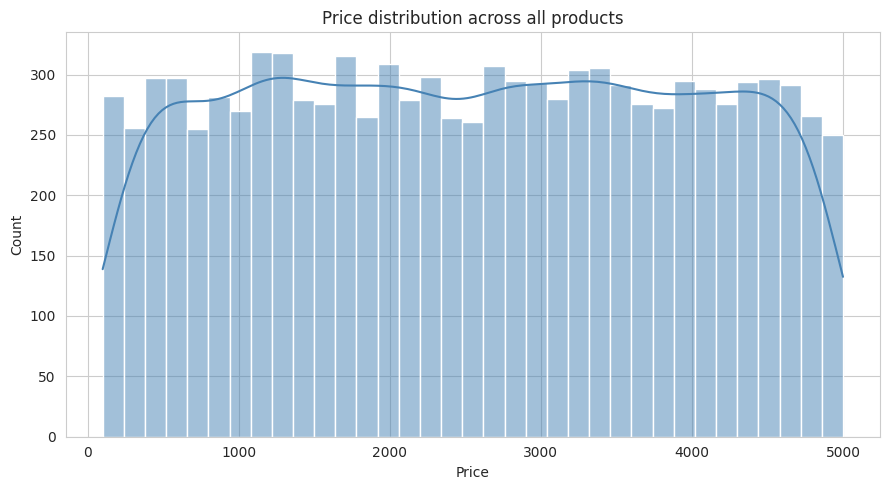

In [52]:
fig, ax = plt.subplots()
sns.histplot(df["Price"], bins=35, kde=True, color="steelblue", ax=ax)
ax.set_title("Price distribution across all products")
ax.set_xlabel("Price")
plt.tight_layout()
plt.show()

## Program 5.2 — Boxplot: Price by Category

/tmp/ipykernel_608/3879810491.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Category", y="Price", palette="Set2", ax=ax)


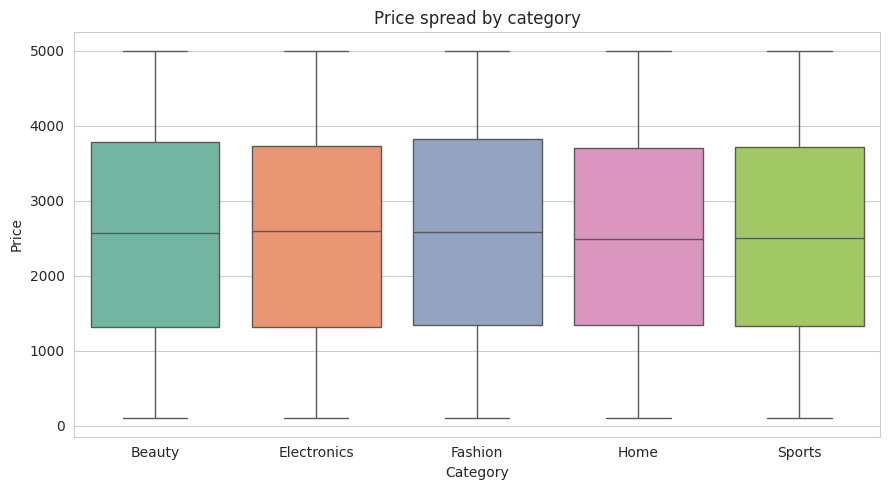

In [53]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="Category", y="Price", palette="Set2", ax=ax)
ax.set_title("Price spread by category")
plt.tight_layout()
plt.show()

## Program 5.3 — Return rate bar chart

In [ ]:
rates = df.groupby("Category", observed=True)["Return_Status"].mean() * 100
rates = rates.sort_values(ascending=False)
overall = df["Return_Status"].mean() * 100

plt.figure(figsize=(9, 5))
bars = plt.bar(rates.index, rates.values, color="#4C72B0", edgecolor="black")
plt.bar_label(bars, fmt="%.1f%%")
plt.axhline(overall, color="red", linestyle="--", label=f"Overall {overall:.1f}%")
plt.title("Return rate by category")
plt.ylabel("Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

## Program 5.4 — Scatter: Price vs Wishlist colored by Return

In [ ]:
fig, ax = plt.subplots()
sns.scatterplot(data=df.sample(800, random_state=1), x="Price", y="Wishlist_Count",
                hue="Return_Status", palette={0: "green", 1: "red"}, alpha=0.6, ax=ax)
ax.set_title("Price vs Wishlist (colored by return)")
plt.tight_layout()
plt.show()

## Program 5.5 — Correlation heatmap

In [ ]:
cols = ["Price", "Wishlist_Count", "Return_History", "Product_Rating", "Return_Status", "Days_Clean"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

## Program 5.6 — Violin plots

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=df, x="Category", y="Product_Rating", inner="quart",
               palette="Pastel1", ax=ax)
ax.set_title("Rating distribution across categories")
plt.tight_layout()
plt.show()

## Program 5.7 — FacetGrid by category

In [ ]:
g = sns.FacetGrid(df, col="Category", col_wrap=3, height=3.5, aspect=1.2)
g.map_dataframe(sns.histplot, x="Price", bins=20, color="crimson")
g.set_titles(col_template="{col_name}")
g.fig.suptitle("Price distribution per category", y=1.02)
plt.show()

## Program 5.8 — Bar chart with CI: Wishlist by return status

In [ ]:
fig, ax = plt.subplots()
sns.barplot(data=df, x="Category", y="Wishlist_Count", hue="Return_Status",
            palette="Blues", errorbar=("ci", 95), ax=ax)
ax.set_title("Avg wishlist count per category (weekday/weekend style)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Program 5.9 — Jointplot of Price vs Rating

In [ ]:
jp = sns.jointplot(data=df, x="Price", y="Product_Rating", kind="hex", color="darkcyan", height=6)
jp.fig.suptitle("Joint distribution - Price vs Rating", y=1.02)
plt.show()

## Program 5.10 — Bubble plot of category summary

In [ ]:
summary = df.groupby("Category", observed=True).agg(
    Avg_Price=("Price", "mean"),
    Return_Rate=("Return_Status", "mean"),
    Count=("Return_Status", "count")
).reset_index()
summary["Return_Rate"] *= 100

plt.figure(figsize=(10, 6))
plt.scatter(summary["Avg_Price"], summary["Return_Rate"],
            s=summary["Count"] / 2, alpha=0.6, edgecolor="black", c="steelblue")
for i, row in summary.iterrows():
    plt.annotate(row["Category"], (row["Avg_Price"], row["Return_Rate"]), ha="center")
plt.xlabel("Average price")
plt.ylabel("Return rate (%)")
plt.title("Category level summary (bubble size = # records)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Final Notes

Going through all 5 units on this dataset. Quick summary of what I actually found:

- Return rate hovers around 50% across all categories — Sports and Beauty slightly higher, Fashion and Home slightly lower. No dramatic difference.
- Price, rating, wishlist count, and prior return history all show near-zero correlation with current return. Single-variable analysis is a dead end here.
- Days_to_Return has about 5% entries with -1, which I treated as missing. When excluded, valid return days spread between 1 and 30 with no clear mode.
- Combining Price and Rating into a "risk label" was actually the most interesting thing — items flagged High risk (expensive + low rating) still only had marginal lift over Mid. So even two-variable interactions aren't strong predictors here.
- The dataset is synthetic so this is expected. With real data I'd try customer-level features (purchase frequency, tenure, past returns per user) and product content signals (size, brand, description quality).